numpy pixels next to vectors, then one drawing exported to every registered format.

Run it as ``python pixels_and_formats.py [OUTPUT_DIR]`` or open ``pixels_and_formats.ipynb`` to see each step.

In [1]:
import sys
import tempfile
import warnings
from pathlib import Path

import numpy as np

import svgwriter as svg

An `Image` takes a numpy array (float 0-1, rows x columns x channels). This one is a generated
plasma pattern, rotated slightly.

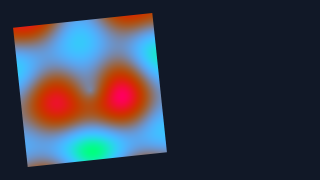

In [2]:
SIZE = 128
y, x = np.mgrid[0:SIZE, 0:SIZE] / SIZE
value = np.sin(10 * x) + np.sin(10 * y + 2) + np.sin(10 * np.hypot(x - 0.5, y - 0.5))
phase = (value - value.min()) / np.ptp(value)
pixels = np.dstack([phase, 1 - phase, 0.5 + 0.5 * np.sin(6 * phase)])

doc = svg.Document(320, 180)
doc.rect(0, 0, 320, 180, fill="#111827")
picture = svg.Image(pixels, 20, 20, 140, 140)
doc += picture.rotate(-6)
doc

`picture.alpha` is a second array for transparency: here a soft round fade.

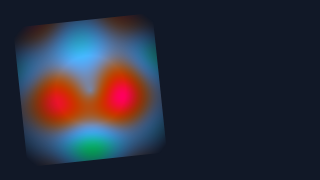

In [3]:
picture.alpha = np.clip(1.6 - 2.4 * np.hypot(x - 0.5, y - 0.5), 0, 1)
doc

Vectors sit beside the pixels, and any element can be rasterized back into an `Image` with
`to_image`, then placed and scaled like one.

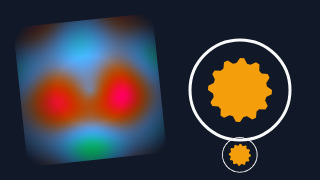

In [4]:
vector = doc.group(stroke="#f9fafb", stroke_width=3, fill="none")
vector.add(svg.circle(240, 90, 50))
vector.add(svg.builder.gear(240, 90, 32, teeth=12, fill="#f59e0b", stroke="none"))
snapshot = vector.to_image(scale=0.5)
doc += snapshot.place(240, 155) * 0.35
doc

Save the SVG, then export the same drawing to every registered format.
Pass a folder as the first argument to choose where the files go.

In [5]:
args = sys.argv[1:2]
out = Path(args[0]) if args and not args[0].startswith("-") else Path(tempfile.mkdtemp(prefix="svgwriter-"))
doc.save(out / "pixels_and_formats.svg")
formats = out / "formats"
formats.mkdir(exist_ok=True)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name, exporter in svg.export.exporters().items():
        extension = exporter.extensions[0] if exporter.extensions else f".{name}"
        doc.save(formats / f"drawing{extension}", format=name)
print("exported:", ", ".join(sorted(path.suffix for path in formats.iterdir())))

exported: .bmp, .docx, .dxf, .eps, .excalidraw, .gcode, .gif, .hpgl, .html, .icns, .ico, .jpg, .pdf, .png, .ppm, .pptx, .svg, .svgz, .tikz, .webp, .xlsx
